<div style="text-align:center; border-radius:20px; padding:25px; color:white; margin:0; font-family:sans-serif; background:#1b002a; box-shadow:0px 6px 18px rgba(0,0,0,0.35); margin-bottom:1em;">
          <div style="font-size:200%; color:#FEE100; font-weight:700;">
            millionaire-habits-dataset-ETL,EDA,Visualize,Model
          </div>
        </div>
        

In [1]:
import os
main_csv_local_path = 'correlations.csv'
DATA_DIR = ''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == main_csv_local_path:
            DATA_DIR = os.path.join(dirname, filename)
            print(DATA_DIR)


/kaggle/input/datasets/datascikhan/millionaire-habits-dataset/correlations.csv


=== A) LOAD + VALIDATE ===
Loaded dataset shape: (227, 2)
Expected columns: ['variable', 'correlation_with_millionaire_status']
Actual columns: ['variable', 'correlation_with_millionaire_status']

=== B) DATA AUDIT ===
Dataset Shape: (227, 2)
Memory Usage (deep=True):
Index                                    132
variable                               15569
correlation_with_millionaire_status     1816
dtype: int64
Duplicate rows count: 0

Null Audit Table:
                                column  null_count  null_pct  non_null_count
0                             variable           0  0.000000             227
1  correlation_with_millionaire_status           1  0.440529             226

Detected Types -> Numeric: ['correlation_with_millionaire_status'], Categorical: ['variable'], Datetime: []

Cardinality for variable: 227 unique values
variable
millionaire_status                 1
net_worth_percentile               1
portfolio_diversification_score    1
investment_income_ratio            

/tmp/ipykernel_16/2866740045.py:47: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(sample, errors='coerce')


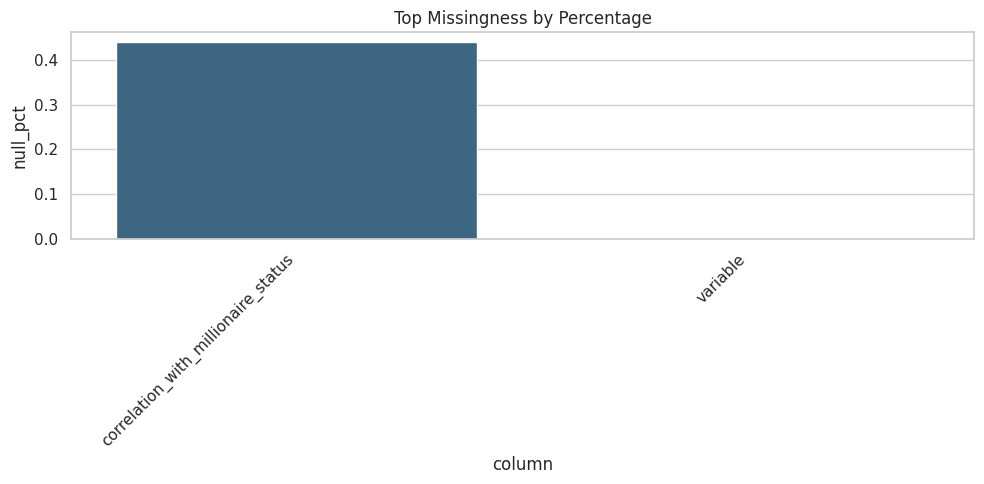

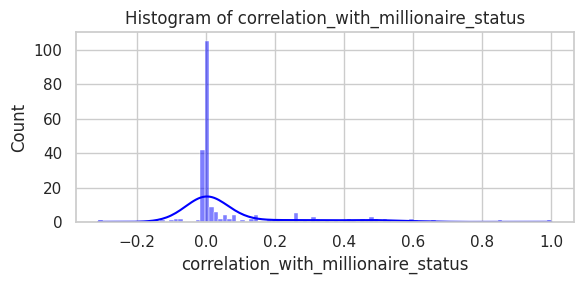

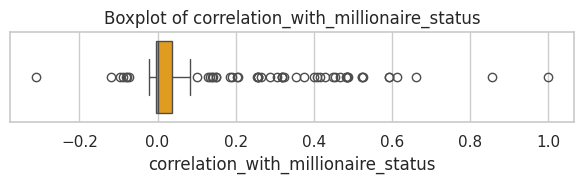

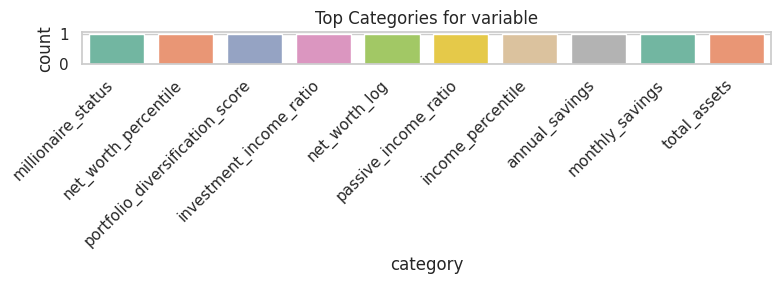


=== F) FEATURE ENGINEERING ===

=== G) FINAL ARTIFACT OUTPUT ===
Before shape: (227, 2)
After shape: (227, 7)
Data Quality Summary:
- Duplicates removed: 0
- Detected datetime cols: []
- Total missing after cleaning: 0

Cleaned Data Head:
                          variable  correlation_with_millionaire_status  correlation_with_millionaire_status__was_missing  variable__was_missing  correlation_with_millionaire_status__winsor  variable__len  variable__words
0               millionaire_status                             1.000000                                                 0                      0                                     0.648933             18                1
1             net_worth_percentile                             0.856205                                                 0                      0                                     0.648933             20                1
2  portfolio_diversification_score                             0.661341                       

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Global Configuration
DATASET_NAME = "datascikhan/millionaire-habits-dataset"
EXACT_COLUMNS = ["variable", "correlation_with_millionaire_status"]
TARGET_COL = None

np.random.seed(42)
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

def safe_read_csv(path):
    try:
        df = pd.read_csv(path)
        return df
    except Exception as e:
        print(f"Error reading CSV: {e}")
        return pd.DataFrame()

def audit_missingness(df):
    audit_list = []
    for col in df.columns:
        null_count = df[col].isnull().sum()
        null_pct = (null_count / len(df)) * 100 if len(df) > 0 else 0
        non_null_count = df[col].notnull().sum()
        audit_list.append({
            'column': col,
            'null_count': null_count,
            'null_pct': null_pct,
            'non_null_count': non_null_count
        })
    return pd.DataFrame(audit_list)

def detect_column_types(df):
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    datetime_cols = []
    
    for col in categorical_cols:
        sample = df[col].dropna().astype(str).head(20)
        if len(sample) > 0:
            parsed = pd.to_datetime(sample, errors='coerce')
            if parsed.notnull().mean() > 0.7:
                datetime_cols.append(col)
                categorical_cols.remove(col)
                
    return numeric_cols, categorical_cols, datetime_cols

def safe_to_numeric(series):
    return pd.to_numeric(series.astype(str).str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')

def safe_to_datetime(series):
    return pd.to_datetime(series, errors='coerce')

# A) Load + Validate
print("=== A) LOAD + VALIDATE ===")
df = safe_read_csv(DATA_DIR)
print(f"Loaded dataset shape: {df.shape}")

actual_cols = df.columns.tolist()
missing_cols = [c for c in EXACT_COLUMNS if c not in actual_cols]
extra_cols = [c for c in actual_cols if c not in EXACT_COLUMNS]

print(f"Expected columns: {EXACT_COLUMNS}")
print(f"Actual columns: {actual_cols}")
if missing_cols:
    print(f"Missing columns: {missing_cols}")
if extra_cols:
    print(f"Extra columns: {extra_cols}")

# B) Data Audit
print("\n=== B) DATA AUDIT ===")
print(f"Dataset Shape: {df.shape}")
print(f"Memory Usage (deep=True):\n{df.memory_usage(deep=True)}")
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows count: {duplicates_count}")

null_audit = audit_missingness(df)
print("\nNull Audit Table:")
print(null_audit)

numeric_cols, categorical_cols, datetime_cols = detect_column_types(df)
print(f"\nDetected Types -> Numeric: {numeric_cols}, Categorical: {categorical_cols}, Datetime: {datetime_cols}")

# Cardinality audit
for col in categorical_cols:
    print(f"\nCardinality for {col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head(5))

# Numeric stability audit
for col in numeric_cols:
    inf_count = np.isinf(df[col]).sum()
    near_const = df[col].nunique() <= 1
    print(f"Numeric column {col}: inf_count={inf_count}, near_constant={near_const}")

# C) ETL (Safe + Reversible)
print("\n=== C) ETL (SAFE + REVERSIBLE) ===")
df_clean = df.copy()

# Standardize object columns
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean.loc[df_clean[col].isin(["", "NA", "N/A", "null", "None", "nan", "NaN"]), col] = np.nan

# Handle duplicates
initial_len = len(df_clean)
df_clean = df_clean.drop_duplicates(keep='first')
print(f"Dropped {initial_len - len(df_clean)} duplicate rows.")

# Missing value handling & indicators
for col in numeric_cols:
    ind_col = f"{col}__was_missing"
    df_clean[ind_col] = df_clean[col].isnull().astype(int)
    median_val = df_clean[col].median() if df_clean[col].notnull().sum() > 0 else 0
    df_clean[col] = df_clean[col].fillna(median_val)

for col in categorical_cols:
    ind_col = f"{col}__was_missing"
    df_clean[ind_col] = df_clean[col].isnull().astype(int)
    df_clean[col] = df_clean[col].fillna("Missing")

for col in datetime_cols:
    ind_col = f"{col}__was_missing"
    df_clean[ind_col] = df_clean[col].isnull().astype(int)
    df_clean[col] = safe_to_datetime(df_clean[col])

# Outlier handling via IQR (numeric)
for col in numeric_cols:
    if df_clean[col].notnull().sum() > 5:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()
        print(f"Outlier count for {col}: {outliers}")
        
        # Winsorize into new column
        w_lower = df_clean[col].quantile(0.01)
        w_upper = df_clean[col].quantile(0.99)
        df_clean[f"{col}__winsor"] = df_clean[col].clip(lower=w_lower, upper=w_upper)

# D) EDA (Deeper + Kaggle-safe)
print("\n=== D) EDA ===")
if numeric_cols:
    print("\nNumeric Distribution Summary:")
    print(df_clean[numeric_cols].describe().T)
    if len(numeric_cols) >= 2:
        max_num_corr = min(len(numeric_cols), 50)
        cols_to_corr = numeric_cols[:max_num_corr]
        corr_matrix = df_clean[cols_to_corr].corr(method='pearson')
        print("\nPearson Correlation Matrix:")
        print(corr_matrix)
        
        spearman_matrix = df_clean[cols_to_corr].corr(method='spearman')
        print("\nSpearman Correlation Matrix:")
        print(spearman_matrix)
        
        # Detect highly correlated pairs
        high_corr = []
        for i in range(len(cols_to_corr)):
            for j in range(i+1, len(cols_to_corr)):
                val = corr_matrix.iloc[i, j]
                if abs(val) >= 0.85:
                    high_corr.append((cols_to_corr[i], cols_to_corr[j], val))
        if high_corr:
            print("Highly correlated pairs (|r| >= 0.85):", high_corr)

# Target-aware analysis guarded
if TARGET_COL and TARGET_COL in df_clean.columns:
    print(f"\nTarget-aware analysis for TARGET_COL: {TARGET_COL}")
    if pd.api.types.is_numeric_dtype(df_clean[TARGET_COL]):
        print(df_clean[numeric_cols].corrwith(df_clean[TARGET_COL]))
    else:
        print(df_clean.groupby(TARGET_COL)[numeric_cols].mean())
else:
    print("\nNo valid TARGET_COL provided. Skipping target-aware analysis.")

# E) Visualization
print("\n=== E) VISUALIZATION ===")
try:
    fig, axes = plt.subplots(figsize=(10, 5))
    top_missing = null_audit.sort_values(by='null_pct', ascending=False).head(30)
    sns.barplot(data=top_missing, x='column', y='null_pct', hue='column', palette='viridis', legend=False, ax=axes)
    plt.xticks(rotation=45, ha='right')
    plt.title("Top Missingness by Percentage")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Skipping missingness plot due to error: {e}")

# Numeric histograms
for col in numeric_cols[:12]:
    try:
        fig, axes = plt.subplots(figsize=(6, 3))
        sns.histplot(df_clean[col], kde=True, ax=axes, color='blue')
        plt.title(f"Histogram of {col}")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Skipping histplot for {col}: {e}")

# Boxplots for numeric cols
for col in numeric_cols[:12]:
    try:
        fig, axes = plt.subplots(figsize=(6, 2))
        sns.boxplot(x=df_clean[col], ax=axes, color='orange')
        plt.title(f"Boxplot of {col}")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Skipping boxplot for {col}: {e}")

# Categorical countplots
for col in categorical_cols[:6]:
    try:
        fig, axes = plt.subplots(figsize=(8, 3))
        top_cats = df_clean[col].value_counts().head(10).reset_index()
        top_cats.columns = ['category', 'count']
        sns.barplot(data=top_cats, x='category', y='count', hue='category', palette='Set2', legend=False, ax=axes)
        plt.xticks(rotation=45, ha='right')
        plt.title(f"Top Categories for {col}")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Skipping countplot for {col}: {e}")

# Correlation heatmap
if len(numeric_cols) >= 2:
    try:
        fig, axes = plt.subplots(figsize=(8, 6))
        sns.heatmap(df_clean[numeric_cols[:20]].corr(), annot=False, cmap='coolwarm', ax=axes)
        plt.title("Correlation Heatmap")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Skipping heatmap: {e}")

# F) Lightweight Feature Engineering
print("\n=== F) FEATURE ENGINEERING ===")
for col in datetime_cols:
    try:
        df_clean[f"{col}__year"] = df_clean[col].dt.year
        df_clean[f"{col}__month"] = df_clean[col].dt.month
        df_clean[f"{col}__dayofweek"] = df_clean[col].dt.dayofweek
    except Exception as e:
        print(f"Error engineering datetime features for {col}: {e}")

for col in categorical_cols:
    try:
        df_clean[f"{col}__len"] = df_clean[col].astype(str).str.len()
        df_clean[f"{col}__words"] = df_clean[col].astype(str).str.split().str.len()
    except Exception as e:
        print(f"Error engineering text features for {col}: {e}")

# G) Final Artifact Output
print("\n=== G) FINAL ARTIFACT OUTPUT ===")
print(f"Before shape: {df.shape}")
print(f"After shape: {df_clean.shape}")
print("Data Quality Summary:")
print(f"- Duplicates removed: {duplicates_count}")
print(f"- Detected datetime cols: {datetime_cols}")
print(f"- Total missing after cleaning: {df_clean.isnull().sum().sum()}")
print("\nCleaned Data Head:")
print(df_clean.head())
